# 9. Hierarchical Clustering / Hiyerarşik Kümeleme

**English theory:** [Classification](../Classification.md) · **Türkçe teori:** [Sınıflandırma](../Classification.tr.md) · [Notebook index / dizin](../README.md)

Build a hierarchy from five hand-checkable points, then cluster the same 3,000-point synthetic example as chapter 8. Read dendrogram heights and distinguish linkage methods.

**Türkçe:** Dendrogramdaki birleşmeleri önce küçük örnekte elle doğrulayıp sonra büyük veriye uyguluyoruz. Bu notebook verisini kendisi üretir.

Run **Restart Kernel → Run All** to reproduce every output. Each notebook starts from raw local data and has no dependency on another notebook's variables. Saved tables and figures are actual executed outputs.

**Türkçe:** Sonuçları yeniden üretmek için çekirdeği yeniden başlatıp bütün hücreleri sırayla çalıştırın. Veri dosyaları repoda bulunur; başka bir notebook'un önceden çalıştırılması gerekmez.

In [1]:
from pathlib import Path
import json
import platform
import numpy as np
import pandas as pd
import scipy
import sklearn
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, JSON

# Works when launched from this folder, Classification/, or the repository root.
candidates = [Path.cwd(), *Path.cwd().parents]
CLASSIFICATION_DIR = next(
    folder for base in candidates for folder in (base, base / "Classification")
    if (folder / "Classification.md").is_file()
    and (folder / "datasets" / "data.csv").is_file()
)
SEED = 42
np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.max_columns", 12)
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (9, 4.5), "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "font.size": 11})
versions = {"Python": platform.python_version(), "NumPy": np.__version__,
            "pandas": pd.__version__, "SciPy": scipy.__version__,
            "scikit-learn": sklearn.__version__, "Matplotlib": matplotlib.__version__}
display(pd.Series(versions, name="Environment"))

Python          3.10.11
NumPy            1.26.4
pandas            2.3.3
SciPy            1.13.1
scikit-learn      1.7.2
Matplotlib       3.10.9
Name: Environment, dtype: object

## Distances and linkage / Uzaklık ve bağlantı

Point distance does not by itself specify cluster distance. Single linkage takes the **minimum** cross-cluster distance, complete the **maximum**, average the mean of all cross pairs. Ward instead minimizes the increase in within-cluster squared error:
$$\Delta W(A,B)=\frac{|A||B|}{|A|+|B|}\lVert\mu_A-\mu_B\rVert^2.$$
For SciPy's Euclidean Ward linkage, the plotted merge height is $h=\sqrt{2\Delta W}$, rather than $\Delta W$ itself. Ward requires Euclidean geometry.

**Türkçe:** Aynı noktalarla farklı linkage yöntemleri farklı ağaçlar üretir. Dendrogram yüksekliğini yorumlarken kullanılan yönteme bakmak gerekir; Ward yüksekliği doğrudan iki merkez arasındaki uzaklık değildir.

,A,B,C,D,E
A,0.0000,1.0000,7.0711,7.4330,1.1180
B,1.0000,0.0000,6.4031,6.7268,1.1180
C,7.0711,6.4031,0.0000,0.5000,6.0208
D,7.4330,6.7268,0.5000,0.0000,6.4031
E,1.1180,1.1180,6.0208,6.4031,0.0000


,left_cluster,right_cluster,merge_height,size
new cluster 5,2.0,3.0,0.500000,2.0
new cluster 6,0.0,1.0,1.000000,2.0
new cluster 7,4.0,6.0,1.118034,3.0
new cluster 8,5.0,7.0,6.020797,5.0


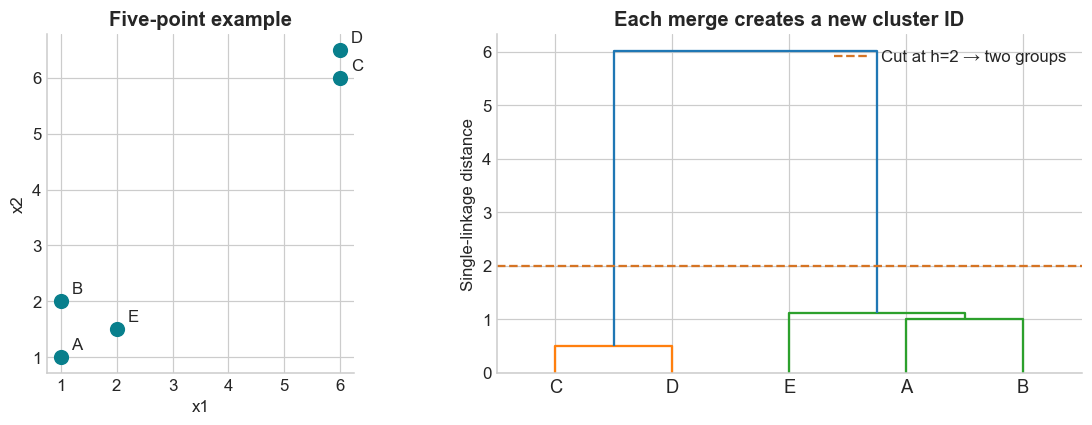

In [2]:
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score

P = np.array([[1., 1.], [1., 2.], [6., 6.], [6., 6.5], [2., 1.5]])
names = ["A", "B", "C", "D", "E"]
display(pd.DataFrame(squareform(pdist(P)), index=names, columns=names).round(4))
Z_small = linkage(P, method="single", metric="euclidean")
assert np.allclose(Z_small[:, 2], [.5, 1., np.sqrt(1.25), np.sqrt(36.25)])
display(pd.DataFrame(Z_small, columns=["left_cluster", "right_cluster", "merge_height", "size"],
                     index=["new cluster 5", "new cluster 6", "new cluster 7", "new cluster 8"]))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(*P.T, s=80, color="#087F8C")
for point, name in zip(P, names):
    axes[0].annotate(name, point, xytext=(7, 5), textcoords="offset points")
axes[0].set(xlabel="x1", ylabel="x2", title="Five-point example", aspect="equal")
dendrogram(Z_small, labels=names, ax=axes[1], color_threshold=2)
axes[1].axhline(2, color="#D57424", linestyle="--", label="Cut at h=2 → two groups")
axes[1].set(ylabel="Single-linkage distance", title="Each merge creates a new cluster ID")
axes[1].legend()
plt.tight_layout()
plt.show()

### Verify Ward's height / Ward yüksekliğini doğrula

Reconstruct the members of each newly merged cluster, calculate the increase in SSE from their sizes and means, and compare every small-example merge with SciPy's height.

**Türkçe:** Birleşmenin üyelerini saklayarak küme boyutu katsayısının ve karekökün rolünü sayısal olarak kontrol ediyoruz.

In [3]:
Z_ward_small = linkage(P, method="ward")
members = {i: [i] for i in range(len(P))}
ward_checks = []
for merge_index, (left, right, height, size) in enumerate(Z_ward_small):
    A, B = members[int(left)], members[int(right)]
    delta = len(A) * len(B) / (len(A) + len(B)) * np.sum((P[A].mean(axis=0) - P[B].mean(axis=0)) ** 2)
    computed_height = np.sqrt(2 * delta)
    assert np.isclose(height, computed_height)
    ward_checks.append({"left": int(left), "right": int(right), "delta_W": delta,
                        "sqrt(2*delta_W)": computed_height, "SciPy_height": height})
    members[len(P) + merge_index] = A + B
display(pd.DataFrame(ward_checks))

,left,right,delta_W,sqrt(2*delta_W),SciPy_height
0,2,3,0.125000,0.500000,0.500000
1,0,1,0.500000,1.000000,1.000000
2,4,6,0.666667,1.154701,1.154701
3,5,7,53.208333,10.315845,10.315845


In [4]:
def make_clouds(seed=42):
    rng = np.random.default_rng(seed)
    return np.vstack([rng.normal(loc=mean, scale=5, size=(1000, 2))
                      for mean in [(25, 25), (55, 60), (55, 15)]])

X = make_clouds(SEED)
assert X.shape == (3000, 2) and np.isfinite(X).all()
print("Unlabelled data shape:", X.shape)
display(pd.DataFrame(X, columns=["x1", "x2"]).describe())

Unlabelled data shape: (3000, 2)


,x1,x2
count,3000.000000,3000.000000
mean,44.948739,33.300857
std,15.182851,20.022397
min,10.177356,-6.945573
25%,27.884693,17.310634
50%,51.751977,25.312297
75%,56.689272,56.652558
max,71.355131,75.297656


## Cut the hierarchy / Hiyerarşiyi kes

For the synthetic clouds, a horizontal cut at height 200 creates three groups. `distance_threshold` and a fixed `n_clusters` are alternative ways to choose a cut. A truncated dendrogram shows the top merges; leaf labels in parentheses are the number of underlying observations.

Adjusted Rand index below compares **two implementations' partitions**, without ground-truth labels. A value of 1 means identical partitions up to arbitrary cluster-number permutations; it is not classification accuracy. General hierarchical linkage has quadratic memory requirements, so this is a small-data demonstration.

**Türkçe:** Etiketsiz gruplama için classification accuracy hesaplanmaz. Buradaki ARI, SciPy ile sklearn'in aynı grupları üretip üretmediğini kontrol eder. Dendrogramın yatay sırası bir zaman ekseni değildir.

1    1000
2     998
3    1002
Name: Cluster size, dtype: int64

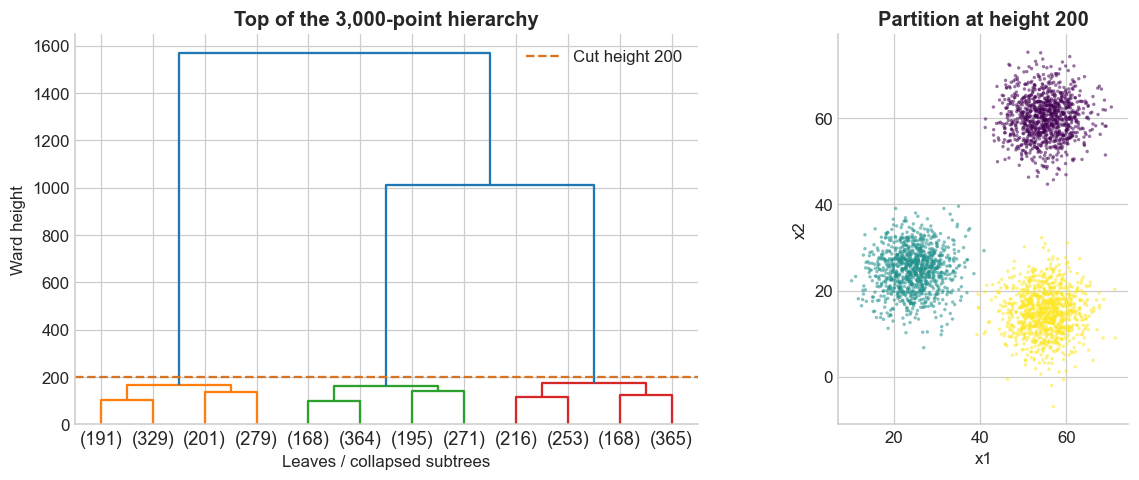

In [5]:
Z = linkage(X, method="ward", metric="euclidean")
scipy_labels = fcluster(Z, t=200, criterion="distance")
sklearn_labels = AgglomerativeClustering(n_clusters=3, linkage="ward").fit_predict(X)
agreement = adjusted_rand_score(scipy_labels, sklearn_labels)
assert len(np.unique(scipy_labels)) == 3 and agreement == 1.0
display(pd.Series(scipy_labels).value_counts().sort_index().rename("Cluster size"))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
dendrogram(Z, truncate_mode="lastp", p=12, show_leaf_counts=True, ax=axes[0], color_threshold=200)
axes[0].axhline(200, color="#D57424", linestyle="--", label="Cut height 200")
axes[0].set(xlabel="Leaves / collapsed subtrees", ylabel="Ward height", title="Top of the 3,000-point hierarchy")
axes[0].legend()
axes[1].scatter(*X.T, c=scipy_labels, cmap="viridis", s=5, alpha=.55, linewidths=0)
axes[1].set(xlabel="x1", ylabel="x2", title="Partition at height 200", aspect="equal")
plt.tight_layout()
plt.show()

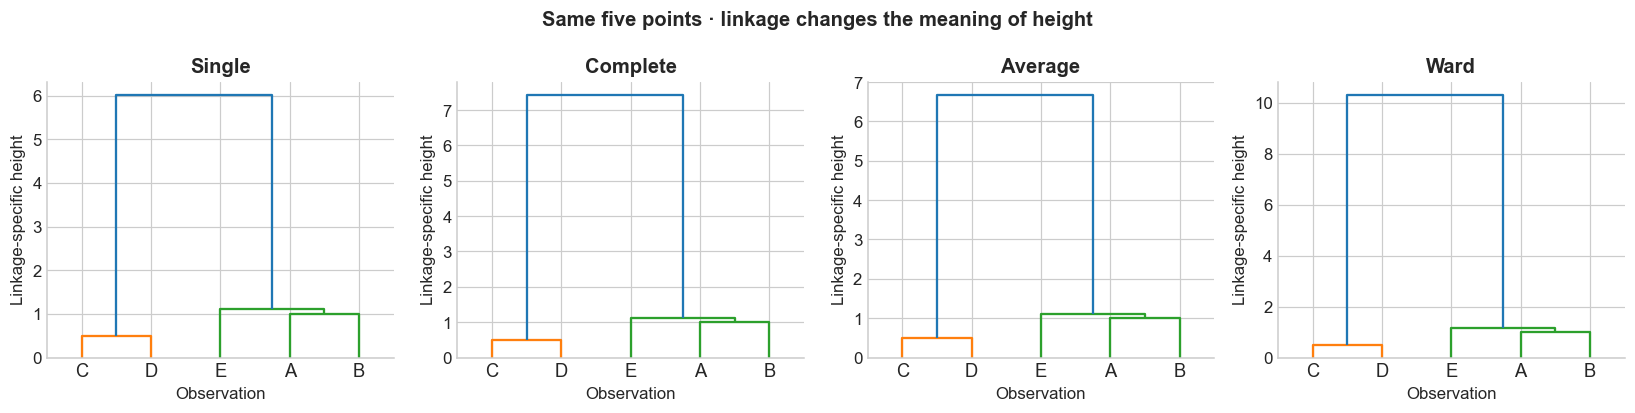

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
for method, ax in zip(["single", "complete", "average", "ward"], axes):
    method_Z = linkage(P, method=method)
    dendrogram(method_Z, labels=names, ax=ax)
    ax.set(title=method.title(), xlabel="Observation", ylabel="Linkage-specific height")
fig.suptitle("Same five points · linkage changes the meaning of height", fontweight="bold")
plt.tight_layout()
plt.show()

## Measured result / Ölçülen sonuç

This summary is produced by the cells above; the runner also collects it in `Classification/notebook_results.json`. A single split is an educational experiment, not a guarantee for a different dataset.

**Türkçe:** Aşağıdaki değerler bu notebook'un gerçek çıktısıdır. Farklı veri veya ayrımlarda aynı sonuç garanti edilmez.

In [7]:
results = {"chapter": 9, "rows": len(X), "linkage": "ward", "cut_height": 200,
           "clusters": int(len(np.unique(scipy_labels))),
           "cluster_sizes": pd.Series(scipy_labels).value_counts().sort_index().tolist(),
           "implementation_partition_ARI": float(agreement),
           "five_point_single_heights": Z_small[:, 2].tolist(),
           "small_Ward_height_formula_verified": True}
results["versions"] = versions
display(JSON(results, expanded=True))

<IPython.core.display.JSON object>